           Model  Accuracy  Precision    Recall        F1
0  MultinomialNB  0.651089   0.634470  0.636933  0.617859
1    BernoulliNB  0.485130   0.616678  0.469434  0.467865


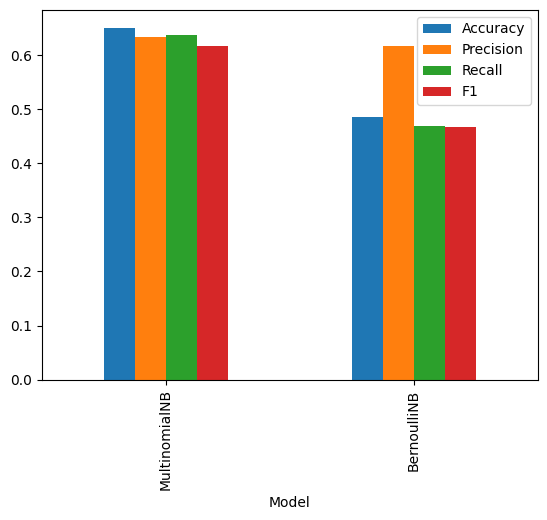

In [7]:
# Algorithm
# 1. Import the required libraries.
# 2. Load the 20 Newsgroups dataset.
# 3. Remove headers, footers and quotations.
# 4. Convert text into numerical features.
# 5. Train the Multinomial Naive Bayes model.
# 6. Predict results and calculate evaluation metrics.
# 7. Convert text into binary features.
# 8. Train the Bernoulli Naive Bayes model.
# 9. Predict results and calculate evaluation metrics.
# 10. Compare both models using a table.
# 11. Plot a bar chart of model performance.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import *

tr = fetch_20newsgroups(subset='train', remove=('headers','footers','quotes'))
te = fetch_20newsgroups(subset='test', remove=('headers','footers','quotes'))

R = []
for model, binary in [(MultinomialNB(), False), (BernoulliNB(), True)]:
    v = CountVectorizer(stop_words='english', min_df=2, binary=binary)
    X = v.fit_transform(tr.data)
    T = v.transform(te.data)
    model.fit(X, tr.target)
    p = model.predict(T)

    R.append([model.__class__.__name__, accuracy_score(te.target, p),
              precision_score(te.target, p, average='macro', zero_division=0),
              recall_score(te.target, p, average='macro', zero_division=0),
              f1_score(te.target, p, average='macro', zero_division=0)])

df = pd.DataFrame(R, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'])
print(df)
df.set_index('Model').plot.bar()
plt.show()

